# Traice: explore the evidence graph

This walkthrough examines the checked-in snapshot and, when the stack is running, queries its API. It is a bounded educational sample, not a representative news dataset or a truth-verification system. See [data provenance](data/README.md) for source links, collection date, and constraints.

## Setup
Run from the repository root. The offline cells need Python and `matplotlib`; install notebook tools separately with `python -m pip install jupyter matplotlib`. For the optional graph queries, start the Compose stack and import the snapshot using the README, then launch Jupyter with `TRAICE_NOTEBOOK_LIVE=1`. The notebook sends only local GET requests and does not change graph data.

In [1]:
import json
import os
from collections import Counter
from pathlib import Path
from urllib.error import URLError
from urllib.request import urlopen

import matplotlib.pyplot as plt

snapshot = json.loads(Path("data/articles.json").read_text(encoding="utf-8"))
articles = snapshot["articles"]
print("Snapshot:", snapshot["collected_at"])
print("Articles:", len(articles))
print("Articles with a resolved paper link:", sum(bool(row["papers"]) for row in articles))

Snapshot: 2026-11-02T12:34:59.500733+00:00
Articles: 232
Articles with a resolved paper link: 12


## Source composition
Counts reflect the collected snapshot, not all articles published by each source. The collection uses selected feeds and one manually checked example; its publisher mix is not representative.

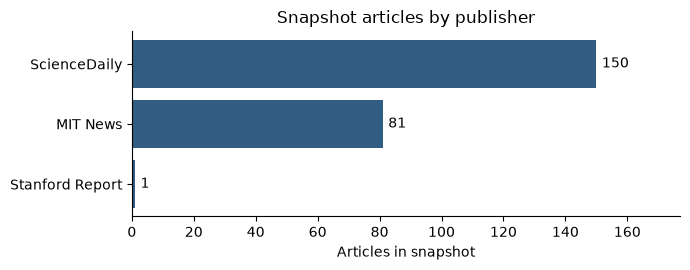

In [2]:
counts = Counter(article["publisher"]["name"] for article in articles)
labels, values = zip(*sorted(counts.items(), key=lambda item: item[1]))
fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(labels, values, color="#315d82")
ax.bar_label(bars, padding=4)
ax.set(xlabel="Articles in snapshot", title="Snapshot articles by publisher")
ax.set_xlim(0, max(values) * 1.18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Follow a documented link
The benchmark example was manually checked against the source page. The stored original linked URL can differ from OpenAlex's canonical paper URL; the link itself does not verify every claim in the article.

In [3]:
example = next(row for row in articles if row["id"] == "1df7478eaeec06c0")
print("Article:", example["title"])
print("Source:", example["url"])
for paper in example["papers"]:
    print("Paper:", paper["title"])
    print("Original link:", paper.get("linked_url", "not recorded"))
    print("Canonical work:", paper["url"])

Article: Researchers work to squash ‘fantastic bugs’ hidden in AI benchmarks
Source: https://news.stanford.edu/stories/2025/12/ai-benchmarks-flaws-models-bugs-research
Paper: Fantastic Bugs and Where to Find Them in AI Benchmarks
Original link: https://arxiv.org/abs/2511.16842
Canonical work: https://doi.org/10.52202/085713-2118


## Explore graph paths through the API
The API query uses the graph loaded from the snapshot. The first request follows Article → Publisher and Article → Paper; the second traverses Article → Topic ← Article. Related articles share a feed topic, not necessarily an event or paper. If the stack is unavailable, the cell reports that and the offline exploration above remains usable.

In [4]:
def local_get(path):
    if os.getenv("TRAICE_NOTEBOOK_LIVE") != "1":
        print("Graph API check skipped; set TRAICE_NOTEBOOK_LIVE=1 after starting Traice.")
        return None
    try:
        with urlopen("http://127.0.0.1:8080" + path, timeout=5) as response:
            return json.load(response)
    except (URLError, TimeoutError, ConnectionError) as exc:
        print("Local graph API unavailable; start and seed Compose to run graph queries:", exc)
        return None

evidence = local_get("/api/articles/1df7478eaeec06c0/evidence")
if evidence:
    print(json.dumps(evidence, indent=2, ensure_ascii=False)[:3000])
related = local_get("/api/articles/1df7478eaeec06c0/related?limit=3")
if related:
    print(json.dumps(related, indent=2, ensure_ascii=False)[:3000])

Graph API check skipped; set TRAICE_NOTEBOOK_LIVE=1 after starting Traice.
Graph API check skipped; set TRAICE_NOTEBOOK_LIVE=1 after starting Traice.


## Next steps
Use `/docs` for the remaining endpoints and the guarded natural-language request. Run `scripts/graph_analysis.py` for GDS and `scripts/topic_classifier.py` for the time-split ML exercise. Feed categories are coarse; missing links and empty results do not establish that no supporting research exists.